In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("Travel (1).csv")

In [3]:
df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [4]:
df.shape

(4888, 20)

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

In [7]:
df.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                         float64
TypeofContact                   str
CityTier                      int64
DurationOfPitch             float64
Occupation                      str
Gender                          str
NumberOfPersonVisiting        int64
NumberOfFollowups           float64
ProductPitched                  str
PreferredPropertyStar       float64
MaritalStatus                   str
NumberOfTrips               float64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting    float64
Designation                     str
MonthlyIncome               float64
dtype: object

In [8]:
df['ProdTaken'].value_counts()

ProdTaken
0    3968
1     920
Name: count, dtype: int64

In [9]:
df['Gender'].value_counts()

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64

In [10]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64

In [11]:
df['Gender']=df['Gender'].replace('Fe Male','Female')

In [12]:
df['Gender'].value_counts()

Gender
Male      2916
Female    1972
Name: count, dtype: int64

In [13]:
df['MaritalStatus']=df['MaritalStatus'].replace('Single','Unmarried')

In [14]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married      2340
Unmarried    1598
Divorced      950
Name: count, dtype: int64

In [15]:
# Removing all the null values 

In [16]:
features_with_na=[feature for feature in df.columns if df[feature].isnull().sum()>=1]

In [17]:
features_with_na

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [18]:
df[features_with_na].columns

Index(['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome'],
      dtype='str')

In [19]:
col=['Age', 'TypeofContact', 'DurationOfPitch', 'NumberOfFollowups',
       'PreferredPropertyStar', 'NumberOfTrips', 'NumberOfChildrenVisiting',
       'MonthlyIncome']

In [20]:
# access only numerical column 

In [21]:
df_numeric=df[features_with_na][col].select_dtypes('float64','int64')

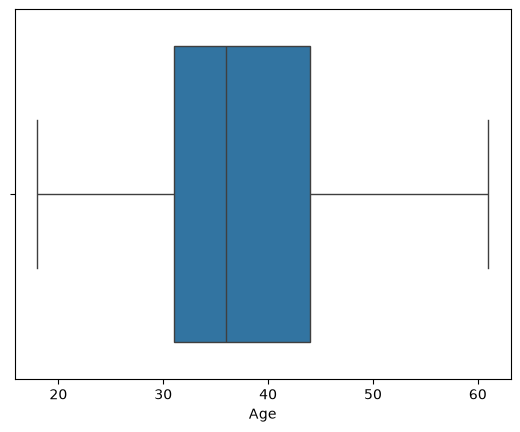

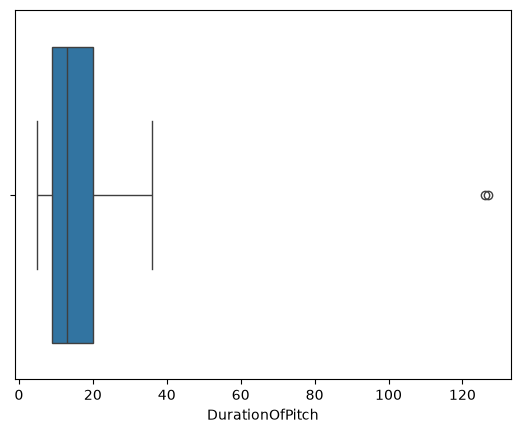

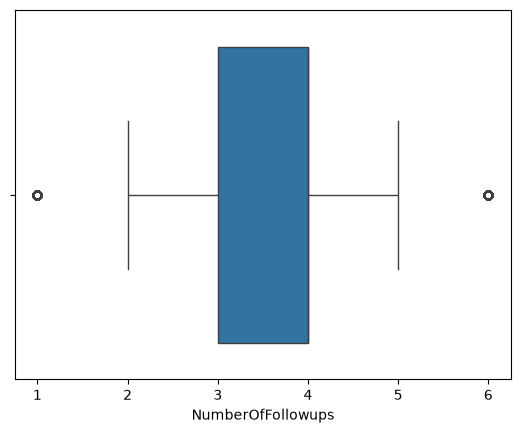

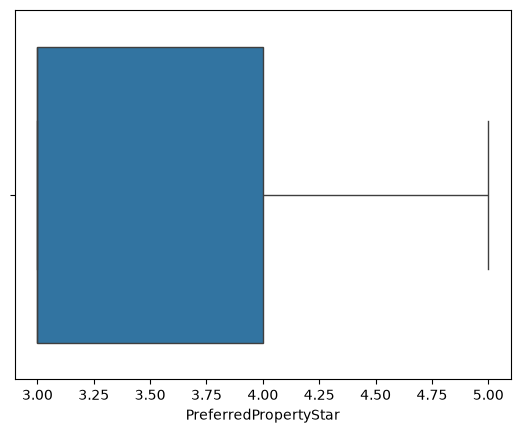

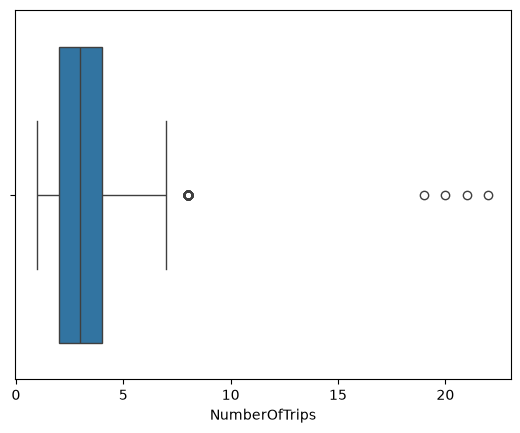

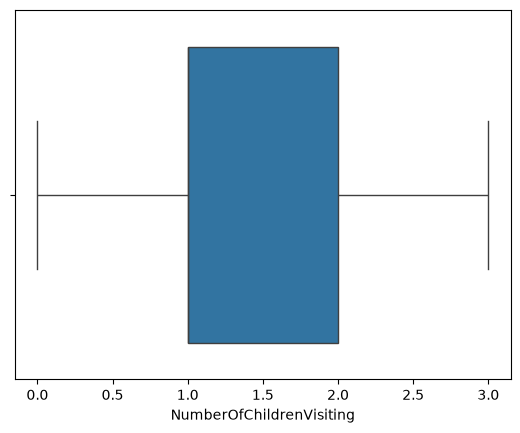

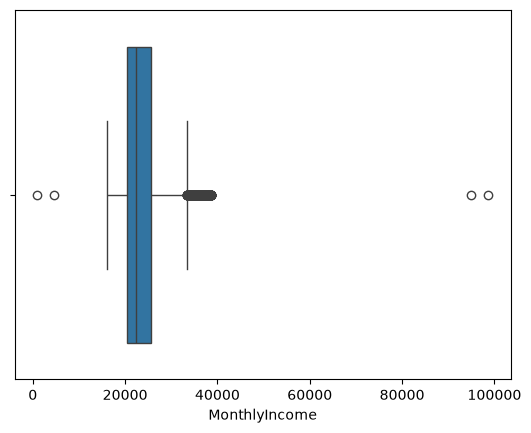

In [22]:
for col in df_numeric.columns:
    plt.figure()
    sns.boxplot(x=df_numeric[col])

In [23]:
features_with_na

['Age',
 'TypeofContact',
 'DurationOfPitch',
 'NumberOfFollowups',
 'PreferredPropertyStar',
 'NumberOfTrips',
 'NumberOfChildrenVisiting',
 'MonthlyIncome']

In [24]:
df['Age']=df['Age'].fillna(df['Age'].mean())
df['DurationOfPitch']=df['DurationOfPitch'].fillna(df['DurationOfPitch'].median())
df['NumberOfFollowups']=df['NumberOfFollowups'].fillna(df['NumberOfFollowups'].median())
df['TypeofContact']=df['TypeofContact'].fillna(df['TypeofContact'].mode().iloc[0])
df['PreferredPropertyStar']=df['PreferredPropertyStar'].fillna(df['PreferredPropertyStar'].mean())
df['NumberOfTrips']=df['NumberOfTrips'].fillna(df['NumberOfTrips'].mean())
df['NumberOfChildrenVisiting']=df['NumberOfChildrenVisiting'].fillna(df['NumberOfChildrenVisiting'].mean())
df['MonthlyIncome']=df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())

In [25]:
df.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [26]:
df.drop("CustomerID",axis=1,inplace=True)

In [27]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfPersonVisiting', 'NumberOfFollowups',
       'ProductPitched', 'PreferredPropertyStar', 'MaritalStatus',
       'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar',
       'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='str')

# Feature Engineering 

In [28]:
df['TotalVisiting']=df['NumberOfPersonVisiting']+df['NumberOfChildrenVisiting']

In [29]:
df.drop(columns=['NumberOfPersonVisiting','NumberOfChildrenVisiting'],inplace=True)

In [30]:
df.columns

Index(['ProdTaken', 'Age', 'TypeofContact', 'CityTier', 'DurationOfPitch',
       'Occupation', 'Gender', 'NumberOfFollowups', 'ProductPitched',
       'PreferredPropertyStar', 'MaritalStatus', 'NumberOfTrips', 'Passport',
       'PitchSatisfactionScore', 'OwnCar', 'Designation', 'MonthlyIncome',
       'TotalVisiting'],
      dtype='str')

In [31]:
# model Training 

In [32]:
X=df.drop('ProdTaken',axis=1)
y=df['ProdTaken']

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [35]:
# column Transformer=used to apply different preprocessing technique on different column 

In [36]:
from sklearn.compose import ColumnTransformer

In [37]:
cat_feature=X.select_dtypes(include='str').columns
num_feature=X.select_dtypes(exclude='str').columns

In [38]:
df[cat_feature]

,TypeofContact,Occupation,Gender,ProductPitched,MaritalStatus,Designation
0,Self Enquiry,Salaried,Female,Deluxe,Unmarried,Manager
1,Company Invited,Salaried,Male,Deluxe,Divorced,Manager
2,Self Enquiry,Free Lancer,Male,Basic,Unmarried,Executive
3,Company Invited,Salaried,Female,Basic,Divorced,Executive
4,Self Enquiry,Small Business,Male,Basic,Divorced,Executive
...,...,...,...,...,...,...
4883,Self Enquiry,Small Business,Male,Deluxe,Unmarried,Manager
4884,Company Invited,Salaried,Male,Basic,Unmarried,Executive
4885,Self Enquiry,Salaried,Female,Standard,Married,Senior Manager
4886,Self Enquiry,Small Business,Male,Basic,Unmarried,Executive


In [39]:
df[num_feature]

,Age,CityTier,DurationOfPitch,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,MonthlyIncome,TotalVisiting
0,41.000000,3,6.0,3.0,3.0,1.0,1,2,1,20993.0,3.0
1,49.000000,1,14.0,4.0,4.0,2.0,0,3,1,20130.0,5.0
2,37.000000,1,8.0,4.0,3.0,7.0,1,3,0,17090.0,3.0
3,33.000000,1,9.0,3.0,3.0,2.0,1,5,1,17909.0,3.0
4,37.622265,1,8.0,3.0,4.0,1.0,0,5,1,18468.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...
4883,49.000000,3,9.0,5.0,4.0,2.0,1,1,1,26576.0,4.0
4884,28.000000,1,31.0,5.0,3.0,3.0,1,3,1,21212.0,6.0
4885,52.000000,3,17.0,4.0,4.0,7.0,0,1,1,31820.0,7.0
4886,19.000000,3,16.0,4.0,3.0,3.0,0,5,0,20289.0,5.0


In [40]:
X_train[num_feature].dtypes

Age                       float64
CityTier                    int64
DurationOfPitch           float64
NumberOfFollowups         float64
PreferredPropertyStar     float64
NumberOfTrips             float64
Passport                    int64
PitchSatisfactionScore      int64
OwnCar                      int64
MonthlyIncome             float64
TotalVisiting             float64
dtype: object

In [41]:
X_train[cat_feature].dtypes

TypeofContact     str
Occupation        str
Gender            str
ProductPitched    str
MaritalStatus     str
Designation       str
dtype: object

In [42]:
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [43]:
# create an object of both preprocessing 

In [44]:
numeric_transformer=StandardScaler()
oh_transformer=OneHotEncoder()

In [45]:
preprocessor=ColumnTransformer(
    [
        ("OneHotEncoder",oh_transformer,cat_feature),
        ("StandardScaler",numeric_transformer,num_feature)
    ]
)

In [46]:
# Apply transformation on training data 

In [47]:
X_train=preprocessor.fit_transform(X_train)
X_test=preprocessor.transform(X_test)

In [48]:
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier 
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [49]:
models={
    "Random Forest":RandomForestClassifier(),
    "Ada boost":AdaBoostClassifier(),
    "Gradient boost":GradientBoostingClassifier(),
    "Decision tree":DecisionTreeClassifier(),
    "Xgboost":XGBClassifier()
}

In [50]:
for i in range(len(list(models))):
    model=list(models.values())[i]

    # model trining 
    model.fit(X_train,y_train)

    # make prediction 
    y_pred_train=model.predict(X_train)
    y_pred_test=model.predict(X_test)

    print(list(models.keys())[i])

    print("Training accuracy")
    print(f"Accuracy={accuracy_score(y_train,y_pred_train)}")
    print(f"precision={precision_score(y_train,y_pred_train)}")
    print(f"recall={recall_score(y_train,y_pred_train)}")
    print(f"f1-score={f1_score(y_train,y_pred_train)}")

    print("Testing accuracy")
    print(f"Accuracy={accuracy_score(y_test,y_pred_test)}")
    print(f"precision={precision_score(y_test,y_pred_test)}")
    print(f"recall={recall_score(y_test,y_pred_test)}")
    print(f"f1-score={f1_score(y_test,y_pred_test)}")

    print("------------------------------------------------")

Random Forest
Training accuracy
Accuracy=1.0
precision=1.0
recall=1.0
f1-score=1.0
Testing accuracy
Accuracy=0.9233128834355828
precision=0.967741935483871
recall=0.6282722513089005
f1-score=0.7619047619047619
------------------------------------------------
Ada boost
Training accuracy
Accuracy=0.8506393861892583
precision=0.7935222672064778
recall=0.26886145404663925
f1-score=0.4016393442622951
Testing accuracy
Accuracy=0.8404907975460123
precision=0.7868852459016393
recall=0.2513089005235602
f1-score=0.38095238095238093
------------------------------------------------
Gradient boost
Training accuracy
Accuracy=0.8936061381074168
precision=0.8735083532219571
recall=0.5020576131687243
f1-score=0.6376306620209059
Testing accuracy
Accuracy=0.8588957055214724
precision=0.7731958762886598
recall=0.39267015706806285
f1-score=0.5208333333333334
------------------------------------------------
Decision tree
Training accuracy
Accuracy=1.0
precision=1.0
recall=1.0
f1-score=1.0
Testing accuracy
A

In [51]:
from sklearn.model_selection import RandomizedSearchCV

In [52]:
from xgboost import XGBClassifier

In [53]:
xgb_data={
    "n_estimators":[100,200,500,700],
    "max_depth":[3,5,7,10],
    "learning_rate":[0.1,0.2,0.01,0.05]
}

In [54]:
xgb_model=XGBClassifier()

In [55]:
best_params=RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_data,
    cv=5,
    random_state=42
)

In [56]:
best_params.fit(X_train,y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.1, 0.2, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attri

In [57]:
best_params.best_params_

{'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.2}

In [58]:
best_params.best_score_

np.float64(0.9317135549872123)

In [59]:
models={
    "Xgboost":XGBClassifier()
}

In [60]:
for i in range(len(list(models))):
    model=list(models.values())[i]

    # model trining 
    model.fit(X_train,y_train)

    # make prediction 
    y_pred_train=model.predict(X_train)
    y_pred_test=model.predict(X_test)

    print(list(models.keys())[i])

    print("Training accuracy")
    print(f"Accuracy={accuracy_score(y_train,y_pred_train)}")
    print(f"precision={precision_score(y_train,y_pred_train)}")
    print(f"recall={recall_score(y_train,y_pred_train)}")
    print(f"f1-score={f1_score(y_train,y_pred_train)}")

    print("Testing accuracy")
    print(f"Accuracy={accuracy_score(y_test,y_pred_test)}")
    print(f"precision={precision_score(y_test,y_pred_test)}")
    print(f"recall={recall_score(y_test,y_pred_test)}")
    print(f"f1-score={f1_score(y_test,y_pred_test)}")

    print("------------------------------------------------")

Xgboost
Training accuracy
Accuracy=0.9997442455242966
precision=1.0
recall=0.9986282578875172
f1-score=0.9993136582017845
Testing accuracy
Accuracy=0.9366053169734151
precision=0.951048951048951
recall=0.7120418848167539
f1-score=0.8143712574850299
------------------------------------------------


In [61]:
import joblib 

In [62]:
joblib.dump(preprocessor,'preprocessor.joblib')

['preprocessor.joblib']

In [63]:
joblib.dump(models,'model.joblib')

['model.joblib']